# Interaksi Magnetik Dua Kawat Lingkaran Sebidang (Aproksimasi Dipol, Fluks, Torsi, dan Induktansi Silang)

**Fu'ad Wafa, S.Pd.**  
**Magister Fisika, Universitas Padjadjaran**  
**David J. Griffiths, *Introduction to Electrodynamics*, Edisi ke-4**

---

## 1. Deskripsi Persoalan dan Geometri Sistem

Persoalan ini meninjau dua loop kawat lingkaran tipis yang diletakkan pada bidang yang sama (sebidang / coplanar). Geometri sistem didefinisikan sebagai berikut:

1. **Kawat-1 (Loop 1):**  
   Kawat lingkaran berjejari $a$ dengan pusat diletakkan pada titik asal koordinat $(0, 0, 0)$ pada bidang $xy$. Loop ini mengalirkan arus listrik tunak $I_1$ berarah berlawanan jarum jam jika dipandang dari sumbu $+z$. Momen dipol magnetik kawat-1 dinyatakan oleh:
   $$\mathbf{m}_1 = I_1 \mathbf{A}_1 = I_1 (\pi a^2)\,\hat{\mathbf{z}}$$

2. **Kawat-2 (Loop 2):**  
   Kawat lingkaran berjejari $b$ dengan pusat diletakkan pada posisi $(r, 0, 0)$ pada sumbu $x$ pada bidang yang sama ($z = 0$). Loop ini mengalirkan arus listrik $I_2$ dengan arah sirkulasi yang **searah** dengan kawat-1 (keduanya berputar berlawanan jarum jam terhadap normal bidang $+z$). Momen dipol magnetik kawat-2 dinyatakan oleh:
   $$\mathbf{m}_2 = I_2 \mathbf{A}_2 = I_2 (\pi b^2)\,\hat{\mathbf{z}}$$

3. **Syarat Batas Jarak Jauh (Aproksimasi Dipol):**  
   Jarak antar-pusat kedua lingkaran memenuhi kondisi $r \gg a$ dan $r \gg b$. Kondisi ini memungkinkan medan magnet yang dihasilkan oleh kawat-1 di sekitar kawat-2 dimodelkan secara akurat melalui ekspansi multipol magnetik orde terendah, yaitu medan dipol magnetik murni.

Sasaran analisis matematis meliputi:
- Penentuan induksi medan magnet $\mathbf{B}_1$ di posisi kawat-2 yang dibangkitkan oleh kawat-1.
- Perhitungan fluks magnetik $\Phi_{21}$ yang menembus luasan kawat-2.
- Penentuan torsi mekanik $\boldsymbol{\tau}_2$ yang bekerja pada kawat-2.
- Penurunan koefisien induktansi silang $M$ antara kedua kawat serta pembuktian teorema resiprositas Neumann.


In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import HTML, display
from html import escape

# Tetapan fundamental permeabilitas vakum
mu_0 = 4 * np.pi * 1e-7  # [H/m atau T m / A]

print(f"Permeabilitas Vakum (mu_0) : {mu_0:.6e} H/m")


Permeabilitas Vakum (mu_0) : 1.256637e-06 H/m


## 2. Penurunan Matematis Analitis

### 2.1 Induksi Magnet di Kawat-2 yang Ditimbulkan oleh Kawat-1 (Pertanyaan a)

Dalam elektrodinamika klasik (Griffiths Persamaan 5.88), medan magnet dari suatu dipol magnetik $\mathbf{m}$ pada posisi relatif $\mathbf{r}$ dinyatakan oleh:
$$\mathbf{B}_{\text{dip}}(\mathbf{r}) = \frac{\mu_0}{4\pi r^3}\left[ 3(\mathbf{m} \cdot \hat{\mathbf{r}})\hat{\mathbf{r}} - \mathbf{m} \right]$$

Untuk persoalan ini:
- Momen dipol sumber: $\mathbf{m}_1 = m_1\,\hat{\mathbf{z}} = I_1 (\pi a^2)\,\hat{\mathbf{z}}$.
- Vektor perpindahan dari pusat kawat-1 ke pusat kawat-2: $\mathbf{r} = r\,\hat{\mathbf{x}}$, sehingga $\hat{\mathbf{r}} = \hat{\mathbf{x}}$.

Evaluasi perkalian titik antara orientasi momen dipol dan vektor posisi relatif:
$$\mathbf{m}_1 \cdot \hat{\mathbf{r}} = (m_1\,\hat{\mathbf{z}}) \cdot \hat{\mathbf{x}} = 0$$

Karena kedua kawat terletak pada bidang yang sama ($xy$), vektor posisi berada pada bidang ekuatorial dari dipol kawat-1. Dengan $\mathbf{m}_1 \cdot \hat{\mathbf{r}} = 0$, medan magnet di pusat kawat-2 tereduksi menjadi:
$$\mathbf{B}_1(\mathbf{r}) = \frac{\mu_0}{4\pi r^3}\left[ 3(0)\hat{\mathbf{x}} - \mathbf{m}_1 \right] = -\frac{\mu_0 \mathbf{m}_1}{4\pi r^3}$$

Substitusikan nilai $\mathbf{m}_1 = I_1 \pi a^2 \hat{\mathbf{z}}$:
$$\mathbf{B}_1 = -\frac{\mu_0 I_1 \pi a^2}{4\pi r^3}\,\hat{\mathbf{z}} = -\frac{\mu_0 I_1 a^2}{4 r^3}\,\hat{\mathbf{z}}$$

Besar induksi magnetik di posisi kawat-2 adalah:
$$B_1 = \frac{\mu_0 I_1 a^2}{4 r^3}$$

*Arah Medan:* Tanda negatif menunjukkan bahwa arah medan magnet $\mathbf{B}_1$ menembus bidang tegak lurus ke arah $-\hat{\mathbf{z}}$. Pada bidang ekuatorial di luar loop, garis-garis medan magnet yang keluar dari sisi atas loop kawat-1 melengkung kembali ke bawah untuk menutup sirkuit fluks.

---

### 2.2 Fluks Magnet yang Melewati Kawat-2 (Pertanyaan b)

Fluks magnetik $\Phi_{21}$ yang menembus kawat-2 didefinisikan oleh integral permukaan:
$$\Phi_{21} = \int_{\text{loop 2}} \mathbf{B}_1 \cdot d\mathbf{a}_2$$

Karena dimensi kawat-2 berukuran kecil dibandingkan dengan jarak pemisah ($b \ll r$), medan magnet $\mathbf{B}_1$ dapat dipandang seragam di seluruh luasan penampang kawat-2.
Vektor elemen luas kawat-2 berorientasi ke arah $+z$ sesuai kaidah tangan kanan untuk arah arus $I_2$:
$$\mathbf{A}_2 = (\pi b^2)\,\hat{\mathbf{z}}$$

Maka fluks magnetik total yang melingkupi kawat-2 adalah:
$$\Phi_{21} = \mathbf{B}_1 \cdot \mathbf{A}_2 = \left( -\frac{\mu_0 I_1 a^2}{4 r^3}\,\hat{\mathbf{z}} \right) \cdot (\pi b^2\,\hat{\mathbf{z}}) = -\frac{\mu_0 \pi I_1 a^2 b^2}{4 r^3}$$

Besar nilai skalar fluks magnetik yang menembus kawat-2 dinyatakan oleh:
$$|\Phi_{21}| = \frac{\mu_0 \pi I_1 a^2 b^2}{4 r^3}$$

Tanda minus menandakan bahwa fluks medan magnet yang datang dari kawat-1 berlawanan arah dengan vektor normal permukaan yang ditentukan oleh arah arus kawat-2.

---

### 2.3 Torsi pada Kawat-2 (Pertanyaan c)

Torsi magnetik $\boldsymbol{\tau}_2$ yang dialami oleh suatu loop berarus atau dipol magnetik $\mathbf{m}_2$ di dalam medan luar $\mathbf{B}_1$ dinyatakan oleh perkalian silang:
$$\boldsymbol{\tau}_2 = \mathbf{m}_2 \times \mathbf{B}_1$$

Masukkan vektor momen dipol kawat-2 $\mathbf{m}_2 = I_2 (\pi b^2)\,\hat{\mathbf{z}}$ dan vektor medan luar $\mathbf{B}_1 = -\frac{\mu_0 I_1 a^2}{4 r^3}\,\hat{\mathbf{z}}$:
$$\boldsymbol{\tau}_2 = \left( I_2 \pi b^2\,\hat{\mathbf{z}} \right) \times \left( -\frac{\mu_0 I_1 a^2}{4 r^3}\,\hat{\mathbf{z}} \right)$$

Karena kedua vektor berada pada sumbu yang sama ($\hat{\mathbf{z}} \times \hat{\mathbf{z}} = \mathbf{0}$):
$$\boldsymbol{\tau}_2 = \mathbf{0}$$

Torsi pada kawat-2 bernilai **nol**.

*Analisis Kestabilan:* Energi potensial interaksi dipol adalah $U = -\mathbf{m}_2 \cdot \mathbf{B}_1 = -m_2 (-B_1) = +m_2 B_1 > 0$. Nilai energi bernilai positif maksimum, yang menunjukkan bahwa orientasi sebidang ini berada dalam kondisi **kesetimbangan labil (tidak stabil)** terhadap rotasi kemiringan. Jika kawat-2 diberi simpangan sudut kecil, torsi pemulih akan memutar loop menuju orientasi sejajar medan.

*Gaya Interaksi Antar-Dipol:* Walaupun torsi bernilai nol, terdapat gaya translasi antar-kawat:
$$\mathbf{F}_2 = \nabla(\mathbf{m}_2 \cdot \mathbf{B}_1) = \frac{\partial}{\partial x}\left( -m_2 \frac{\mu_0 m_1}{4\pi x^3} \right)\hat{\mathbf{x}} = \frac{3\mu_0 m_1 m_2}{4\pi r^4}\,\hat{\mathbf{x}} = \frac{3\mu_0 \pi I_1 I_2 a^2 b^2}{4 r^4}\,\hat{\mathbf{x}}$$
Gaya bernilai positif searah $+\hat{\mathbf{x}}$, yang berarti kedua kawat mengalami **gaya tolak-menolak (repulsif)** sebanding dengan $1/r^4$.

---

### 2.4 Induktansi Silang Antara Dua Kawat (Pertanyaan d)

Induktansi silang $M$ mengukur keterkaitan fluks magnetik pada satu loop akibat arus pada loop lainnya:
$$|\Phi_{21}| = M_{21} I_1 \implies M_{21} = \frac{|\Phi_{21}|}{I_1}$$

Substitusikan besar fluks magnetik $|\Phi_{21}|$ dari Bagian 2.2:
$$M_{21} = \frac{1}{I_1}\left( \frac{\mu_0 \pi I_1 a^2 b^2}{4 r^3} \right) = \frac{\mu_0 \pi a^2 b^2}{4 r^3}$$

Berdasarkan teorema resiprositas Neumann dalam magnetostatika, induktansi silang bersifat simetris:
$$M_{12} = M_{21} = M = \frac{\mu_0 \pi a^2 b^2}{4 r^3}$$

Persamaan ini menunjukkan bahwa induktansi silang berbanding lurus dengan kuadrat jari-jari kedua kawat ($a^2 b^2$) dan meluruh sebanding dengan pangkat tiga jarak pemisah ($1/r^3$).


In [2]:
# Verifikasi Simbolik Menggunakan SymPy
a, b, r_sym, I_1, I_2, mu0 = sp.symbols('a b r I_1 I_2 mu_0', positive=True)

# 1. Momen Dipol
m_1 = I_1 * sp.pi * a**2
m_2 = I_2 * sp.pi * b**2

# 2. Vektor Medan Dipol pada Bidang Ekuatorial (theta = pi/2)
# B_dip(r) = (mu_0 / 4*pi*r^3) * [3(m . r_hat)r_hat - m]
# dengan m . r_hat = 0
B_1_z = - (mu0 * m_1) / (4 * sp.pi * r_sym**3)
B_1_simplified = sp.simplify(B_1_z)

# 3. Fluks Magnetik Melalui Kawat-2
A_2 = sp.pi * b**2
Phi_21 = B_1_simplified * A_2
Phi_mag = sp.simplify(sp.Abs(Phi_21))

# 4. Torsi Magnetik tau = m_2 x B_1
# Karena m_2 berarah +z dan B_1 berarah -z, hasil perkalian silang adalah 0
tau_magnitude = sp.simplify(m_2 * sp.Abs(B_1_simplified) * sp.sin(sp.pi)) # Sudut 180 derajat

# 5. Induktansi Silang M
M = sp.simplify(Phi_mag / I_1)

# 6. Gaya Antar Loop F = d/dr [ m_2 * B_1 ]
U = - m_2 * B_1_simplified # Energi potensial
F_repulsif = sp.simplify(- sp.diff(U, r_sym))

print("=== HASIL VALIDASI SIMBOLIK SYMPY ===")
print(f"Medan B_1 di kawat-2        : B_1_z = {B_1_simplified}")
print(f"Fluks Magnetik Phi_21       : {Phi_21}")
print(f"Besar Fluks |Phi_21|        : {Phi_mag}")
print(f"Besar Torsi tau_2           : {tau_magnitude} (Torsi bernilai nol)")
print(f"Induktansi Silang M         : {M}")
print(f"Gaya Interaksi F(r)         : {F_repulsif} (Repulsif ~ 1/r^4)")


=== HASIL VALIDASI SIMBOLIK SYMPY ===
Medan B_1 di kawat-2        : B_1_z = -I_1*a**2*mu_0/(4*r**3)
Fluks Magnetik Phi_21       : -pi*I_1*a**2*b**2*mu_0/(4*r**3)
Besar Fluks |Phi_21|        : pi*I_1*a**2*b**2*mu_0/(4*r**3)
Besar Torsi tau_2           : 0 (Torsi bernilai nol)
Induktansi Silang M         : pi*a**2*b**2*mu_0/(4*r**3)
Gaya Interaksi F(r)         : 3*pi*I_1*I_2*a**2*b**2*mu_0/(4*r**4) (Repulsif ~ 1/r^4)


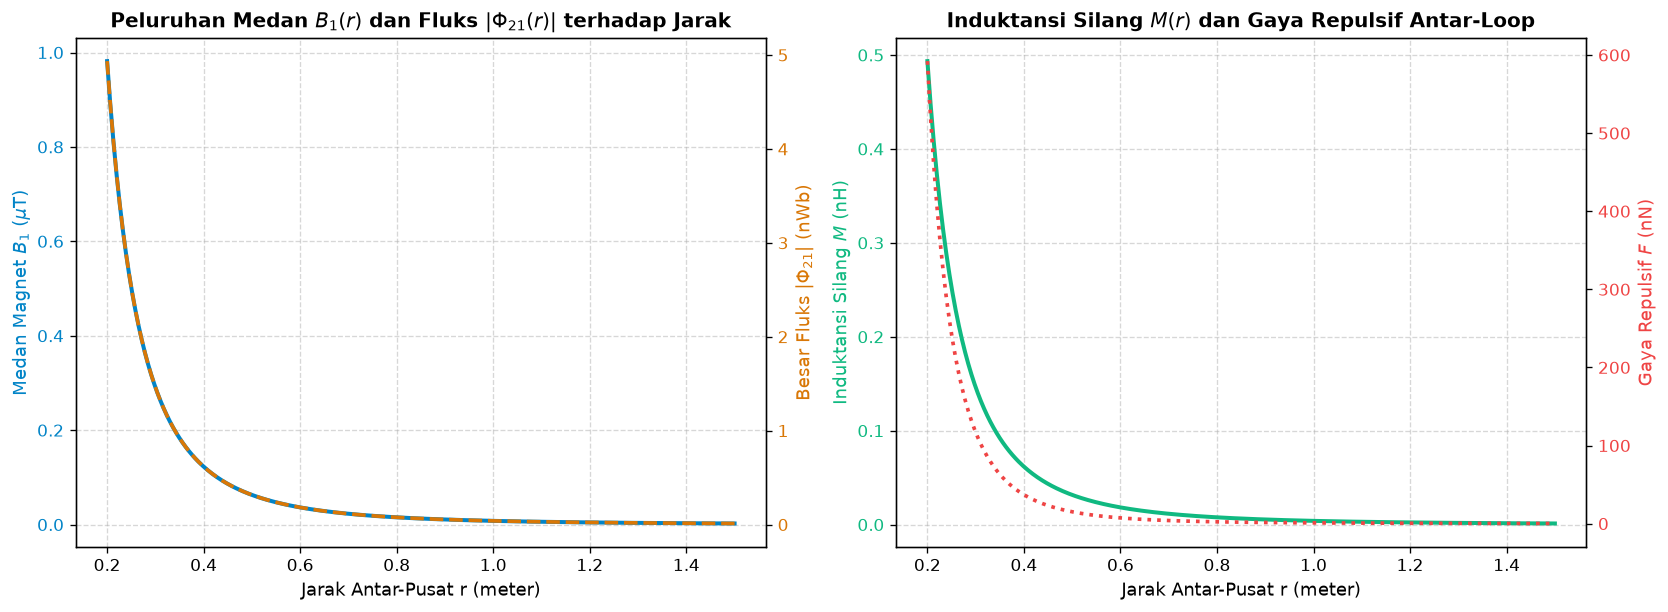

In [3]:
# Visualisasi Numerik Ketergantungan Jarak r terhadap Medan, Fluks, dan Induktansi
a_val = 0.05   # 5 cm
b_val = 0.04   # 4 cm
I1_val = 10.0  # 10 A
I2_val = 8.0   # 8 A

r_range = np.linspace(0.2, 1.5, 400) # Jarak dari 20 cm hingga 1.5 m (r >> a, b)

# Perhitungan Analitis
B1_arr = (mu_0 * I1_val * a_val**2) / (4 * r_range**3)
Phi_arr = (mu_0 * np.pi * I1_val * a_val**2 * b_val**2) / (4 * r_range**3)
M_arr = (mu_0 * np.pi * a_val**2 * b_val**2) / (4 * r_range**3)
F_arr = (3 * mu_0 * np.pi * I1_val * I2_val * a_val**2 * b_val**2) / (4 * r_range**4)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=120)

# Subplot 1: Medan Magnetik B_1 dan Fluks Phi_21
color1 = '#0284c7'
ax1.plot(r_range, B1_arr * 1e6, color=color1, lw=2.4, label=r'Induksi Magnet $B_1$ ($\mu\mathrm{T}$)')
ax1.set_xlabel('Jarak Antar-Pusat r (meter)', fontsize=11)
ax1.set_ylabel(r'Medan Magnet $B_1$ ($\mu\mathrm{T}$)', color=color1, fontsize=11)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1_twin = ax1.twinx()
color2 = '#d97706'
ax1_twin.plot(r_range, Phi_arr * 1e9, color=color2, lw=2.2, linestyle='--', label=r'Besar Fluks $|\Phi_{21}|$ ($\mathrm{nWb}$)')
ax1_twin.set_ylabel(r'Besar Fluks $|\Phi_{21}|$ ($\mathrm{nWb}$)', color=color2, fontsize=11)
ax1_twin.tick_params(axis='y', labelcolor=color2)
ax1.set_title(r'Peluruhan Medan $B_1(r)$ dan Fluks $|\Phi_{21}(r)|$ terhadap Jarak', fontsize=12, fontweight='bold')

# Subplot 2: Induktansi Silang M dan Gaya Repulsif F
color3 = '#10b981'
ax2.plot(r_range, M_arr * 1e9, color=color3, lw=2.4, label=r'Induktansi Silang $M$ ($\mathrm{nH}$)')
ax2.set_xlabel('Jarak Antar-Pusat r (meter)', fontsize=11)
ax2.set_ylabel(r'Induktansi Silang $M$ ($\mathrm{nH}$)', color=color3, fontsize=11)
ax2.tick_params(axis='y', labelcolor=color3)
ax2.grid(True, linestyle='--', alpha=0.5)

ax2_twin = ax2.twinx()
color4 = '#ef4444'
ax2_twin.plot(r_range, F_arr * 1e9, color=color4, lw=2.2, linestyle=':', label=r'Gaya Tolak-Menolak $F$ ($\mathrm{nN}$)')
ax2_twin.set_ylabel(r'Gaya Repulsif $F$ ($\mathrm{nN}$)', color=color4, fontsize=11)
ax2_twin.tick_params(axis='y', labelcolor=color4)
ax2.set_title(r'Induktansi Silang $M(r)$ dan Gaya Repulsif Antar-Loop', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Proyeksi Ruang 3D Interaktif Menggunakan Three.js

Aplikasi visualisasi tiga dimensi di bawah ini memproyeksikan interaksi magnetik antara kedua kawat lingkaran pada bidang sebidang ($xy$):
1. **Loop Kawat-1:** kawat tembaga berjejari $a$ di pusat koordinat dengan panah sirkulasi arus $I_1$ dan vektor momen dipol $\mathbf{m}_1$.
2. **Loop Kawat-2:** kawat perak berjejari $b$ pada jarak $r$ dengan panah sirkulasi arus $I_2$ dan vektor momen dipol $\mathbf{m}_2$.
3. **Garis-Garis Medan Magnetik Dipol:** garis-garis fluks medan magnet yang terpancar dari kawat-1, melengkung melintasi ruang, dan menembus penampang kawat-2 dengan orientasi masuk ($-\hat{\mathbf{z}}$).
4. **Vektor Gaya Interaksi:** panah gaya tolak-menolak aksial (repulsif) pada kawat-2 akibat gradien medan magnetik.

**Panel Pengaturan Interaktif:**
- Slider jari-jari kawat $a$ dan $b$.
- Slider jarak pemisah $r$ ($r \gg a, b$).
- Slider arus $I_1$ dan $I_2$.
- Tombol pembalik polaritas arus (arus searah vs arus berlawanan).
- Sakelar tampilan lapisan vektor medan $\mathbf{B}$, momen dipol $\mathbf{m}$, dan gaya repulsif.
- Kanvas grafik analitis real-time di sudut kanvas yang menghitung nilai eksak $B_1$, $\Phi_{21}$, dan $M$ secara live saat parameter diubah.


In [4]:
# Render Simulasi Tiga Dimensi Interaktif Three.js
threejs_code = r"""<!DOCTYPE html>
<html lang="id">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0, maximum-scale=1.0, user-scalable=no">
  <title>Simulasi 3D Interaksi Dua Loop Kawat Dipol</title>
  <style>
    :root {
      --bg: #ffffff;
      --surface: rgba(255, 255, 255, 0.88);
      --surface-solid: #ffffff;
      --border: rgba(226, 232, 240, 0.85);
      --border-focus: #0284c7;
      
      --c-loop1: #ea580c;      /* Oranye kawat 1 */
      --c-loop2: #0284c7;      /* Biru kawat 2 */
      --c-field: #d97706;      /* Amber garis medan B */
      --c-dipole: #059669;     /* Hijau momen dipol */
      --c-force: #dc2626;      /* Merah gaya Lorentz/interaksi */
      
      --text: #0f172a;
      --text-secondary: #475569;
      --text-muted: #64748b;
      
      --shadow-sm: 0 2px 6px -1px rgba(15, 23, 42, 0.05);
      --shadow-md: 0 12px 28px -8px rgba(15, 23, 42, 0.08), 0 2px 6px -1px rgba(15, 23, 42, 0.03);
      --shadow-lg: 0 20px 40px -12px rgba(15, 23, 42, 0.12), 0 4px 12px -2px rgba(15, 23, 42, 0.04);
      
      --ease-spring: cubic-bezier(0.16, 1, 0.3, 1);
      --ease-smooth: cubic-bezier(0.4, 0, 0.2, 1);
    }

    * {
      box-sizing: border-box;
      margin: 0;
      padding: 0;
      -webkit-tap-highlight-color: transparent;
    }

    html, body {
      width: 100%;
      height: 100%;
      overflow: hidden;
      font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif;
      background: var(--bg);
      color: var(--text);
    }

    #canvas-container {
      position: relative;
      width: 100%;
      height: 100%;
      overflow: hidden;
      display: flex;
    }

    #viewport {
      width: 100%;
      height: 100%;
      display: block;
      outline: none;
    }

    /* ============================================================
       TOP FLOATING TOOLBAR (Antislop + Premium UI)
       ============================================================ */
    .app-toolbar {
      position: absolute;
      top: 14px;
      left: 14px;
      right: 14px;
      display: flex;
      align-items: center;
      justify-content: space-between;
      gap: 10px;
      pointer-events: none;
      z-index: 40;
    }

    .toolbar-brand {
      pointer-events: auto;
      display: inline-flex;
      align-items: center;
      gap: 8px;
      padding: 7px 12px;
      background: var(--surface);
      backdrop-filter: blur(18px) saturate(180%);
      -webkit-backdrop-filter: blur(18px) saturate(180%);
      border: 1px solid var(--border);
      border-radius: 9999px;
      box-shadow: var(--shadow-sm);
    }

    .brand-pulse {
      width: 8px;
      height: 8px;
      border-radius: 50%;
      background: #10b981;
      box-shadow: 0 0 0 3px rgba(16, 185, 129, 0.2);
      animation: pulse-ring 2.5s infinite;
    }

    @keyframes pulse-ring {
      0%, 100% { transform: scale(1); opacity: 1; }
      50% { transform: scale(1.15); opacity: 0.75; }
    }

    .brand-title {
      font-size: 12px;
      font-weight: 700;
      letter-spacing: -0.01em;
      color: var(--text);
      white-space: nowrap;
    }

    .brand-badge {
      font-size: 10px;
      font-weight: 600;
      color: #0284c7;
      background: rgba(2, 132, 199, 0.09);
      padding: 2px 7px;
      border-radius: 9999px;
      letter-spacing: 0.02em;
    }

    .toolbar-actions {
      pointer-events: auto;
      display: inline-flex;
      align-items: center;
      gap: 6px;
      background: var(--surface);
      backdrop-filter: blur(18px) saturate(180%);
      -webkit-backdrop-filter: blur(18px) saturate(180%);
      padding: 4px;
      border: 1px solid var(--border);
      border-radius: 9999px;
      box-shadow: var(--shadow-sm);
    }

    /* Minimum touch target 44px x 44px */
    .toolbar-btn {
      display: inline-flex;
      align-items: center;
      justify-content: center;
      gap: 6px;
      height: 36px;
      min-width: 36px;
      padding: 0 12px;
      border-radius: 9999px;
      font-size: 12px;
      font-weight: 600;
      color: var(--text-secondary);
      background: transparent;
      border: 1px solid transparent;
      cursor: pointer;
      transition: all 0.2s var(--ease-smooth);
      user-select: none;
    }

    .toolbar-btn.icon-only {
      padding: 0;
      width: 36px;
    }

    .toolbar-btn:hover {
      color: var(--text);
      background: rgba(15, 23, 42, 0.04);
    }

    .toolbar-btn:active {
      transform: scale(0.96);
    }

    .toolbar-btn.active {
      background: #0284c7;
      color: #ffffff;
      box-shadow: 0 3px 10px -2px rgba(2, 132, 199, 0.4);
    }

    .toolbar-btn.active .toggle-pill {
      background: rgba(255, 255, 255, 0.3);
    }

    .toggle-pill {
      width: 6px;
      height: 6px;
      border-radius: 50%;
      background: #94a3b8;
      transition: background 0.2s ease;
    }

    .btn-svg {
      width: 15px;
      height: 15px;
      flex-shrink: 0;
    }

    /* ============================================================
       DRAWER / COLLAPSIBLE CONFIGURATION PANEL
       ============================================================ */
    .config-drawer {
      position: absolute;
      top: 66px;
      left: 14px;
      width: 330px;
      max-height: calc(100% - 80px);
      background: var(--surface);
      backdrop-filter: blur(20px) saturate(180%);
      -webkit-backdrop-filter: blur(20px) saturate(180%);
      border: 1px solid var(--border);
      border-radius: 16px;
      box-shadow: var(--shadow-lg);
      display: flex;
      flex-direction: column;
      z-index: 35;
      overflow: hidden;
      transition: transform 0.38s var(--ease-spring), opacity 0.25s var(--ease-smooth), visibility 0.38s;
      transform: translateX(0);
      opacity: 1;
      visibility: visible;
    }

    .config-drawer.is-collapsed {
      transform: translateX(calc(-100% - 24px));
      opacity: 0;
      visibility: hidden;
      pointer-events: none;
    }

    /* Drawer Header */
    .drawer-header {
      display: flex;
      align-items: center;
      justify-content: space-between;
      padding: 12px 16px;
      border-bottom: 1px solid rgba(226, 232, 240, 0.7);
      background: rgba(255, 255, 255, 0.4);
    }

    .drawer-title-group {
      display: flex;
      align-items: center;
      gap: 7px;
    }

    .drawer-title {
      font-size: 13px;
      font-weight: 700;
      letter-spacing: -0.01em;
      color: var(--text);
    }

    .drawer-close-btn {
      display: flex;
      align-items: center;
      justify-content: center;
      width: 32px;
      height: 32px;
      min-height: 32px;
      min-width: 32px;
      border-radius: 8px;
      border: none;
      background: transparent;
      color: var(--text-muted);
      cursor: pointer;
      transition: all 0.15s ease;
    }

    .drawer-close-btn:hover {
      background: rgba(15, 23, 42, 0.06);
      color: var(--text);
    }

    .drawer-close-btn:active {
      transform: scale(0.92);
    }

    /* Drawer Scrollable Content */
    .drawer-content {
      padding: 14px 16px;
      overflow-y: auto;
      flex: 1;
      scrollbar-width: thin;
      scrollbar-color: #cbd5e1 transparent;
    }

    .drawer-content::-webkit-scrollbar {
      width: 5px;
    }
    .drawer-content::-webkit-scrollbar-thumb {
      background: #cbd5e1;
      border-radius: 10px;
    }

    .section-label {
      font-size: 10px;
      font-weight: 700;
      text-transform: uppercase;
      letter-spacing: 0.08em;
      color: var(--text-muted);
      margin: 12px 0 6px;
      padding-bottom: 4px;
      border-bottom: 1px solid rgba(226, 232, 240, 0.7);
    }
    .section-label:first-child {
      margin-top: 0;
    }

    .control-group {
      margin-bottom: 10px;
    }

    .control-label {
      display: flex;
      justify-content: space-between;
      align-items: baseline;
      margin-bottom: 4px;
      font-size: 11.5px;
      color: var(--text-secondary);
      font-weight: 500;
    }

    .control-label span.val {
      color: var(--text);
      font-family: ui-monospace, SFMono-Regular, Menlo, Monaco, Consolas, monospace;
      font-weight: 700;
      font-size: 11.5px;
      background: rgba(15, 23, 42, 0.05);
      padding: 1px 6px;
      border-radius: 5px;
    }

    /* Enhanced Touch-Friendly Range Slider */
    input[type=range] {
      -webkit-appearance: none;
      appearance: none;
      width: 100%;
      height: 6px;
      background: #e2e8f0;
      border-radius: 9999px;
      outline: none;
      margin: 8px 0;
      cursor: pointer;
      transition: background 0.15s ease;
    }
    input[type=range]:hover {
      background: #cbd5e1;
    }
    input[type=range]::-webkit-slider-thumb {
      -webkit-appearance: none;
      appearance: none;
      width: 18px;
      height: 18px;
      border-radius: 50%;
      background: #0284c7;
      border: 2px solid #ffffff;
      box-shadow: 0 2px 6px rgba(2, 132, 199, 0.4);
      cursor: pointer;
      transition: transform 0.15s ease, background 0.15s ease;
    }
    input[type=range]::-webkit-slider-thumb:hover {
      transform: scale(1.15);
      background: #0369a1;
    }
    input[type=range]::-moz-range-thumb {
      width: 18px;
      height: 18px;
      border-radius: 50%;
      background: #0284c7;
      border: 2px solid #ffffff;
      box-shadow: 0 2px 6px rgba(2, 132, 199, 0.4);
      cursor: pointer;
    }

    .btn-row {
      display: flex;
      gap: 6px;
      margin-top: 6px;
    }

    .action-btn {
      flex: 1;
      min-height: 38px;
      padding: 7px 10px;
      background: rgba(2, 132, 199, 0.07);
      border: 1px solid rgba(2, 132, 199, 0.22);
      border-radius: 8px;
      color: var(--text);
      font-size: 11px;
      font-weight: 600;
      cursor: pointer;
      transition: all 0.18s var(--ease-smooth);
      display: inline-flex;
      align-items: center;
      justify-content: center;
    }

    .action-btn:hover {
      background: #0284c7;
      border-color: #0284c7;
      color: #ffffff;
    }

    .action-btn:active {
      transform: scale(0.97);
    }

    .action-btn.active {
      background: #0284c7;
      border-color: #0284c7;
      color: #ffffff;
      box-shadow: 0 2px 8px -1px rgba(2, 132, 199, 0.4);
    }

    /* Touch-Optimized Checkbox Rows (minimum 44px tap zone) */
    .checkbox-row {
      display: flex;
      align-items: center;
      gap: 10px;
      min-height: 40px;
      padding: 4px 6px;
      border-radius: 8px;
      cursor: pointer;
      transition: background 0.15s ease;
      font-size: 11.5px;
      color: var(--text-secondary);
      font-weight: 500;
      user-select: none;
    }

    .checkbox-row:hover {
      background: rgba(15, 23, 42, 0.03);
    }

    .checkbox-row input[type=checkbox] {
      width: 17px;
      height: 17px;
      accent-color: #0284c7;
      cursor: pointer;
      border-radius: 4px;
    }

    /* ============================================================
       GRAPH & METRICS PANEL (Collapsible)
       ============================================================ */
    .graph-panel {
      position: absolute;
      bottom: 14px;
      right: 14px;
      width: 320px;
      background: var(--surface);
      backdrop-filter: blur(20px) saturate(180%);
      -webkit-backdrop-filter: blur(20px) saturate(180%);
      border: 1px solid var(--border);
      border-radius: 16px;
      padding: 12px 14px;
      box-shadow: var(--shadow-lg);
      z-index: 35;
      transition: transform 0.38s var(--ease-spring), opacity 0.25s var(--ease-smooth), visibility 0.38s;
      transform: translateY(0);
      opacity: 1;
      visibility: visible;
    }

    .graph-panel.is-collapsed {
      transform: translateY(calc(100% + 24px));
      opacity: 0;
      visibility: hidden;
      pointer-events: none;
    }

    .graph-header {
      display: flex;
      align-items: center;
      justify-content: space-between;
      margin-bottom: 8px;
    }

    .graph-header h3 {
      font-size: 11px;
      font-weight: 700;
      color: #0284c7;
      text-transform: uppercase;
      letter-spacing: 0.06em;
      display: flex;
      align-items: center;
      gap: 5px;
    }

    #plotCanvas {
      width: 100%;
      height: 125px;
      background: #f8fafc;
      border: 1px solid #e2e8f0;
      border-radius: 8px;
      display: block;
    }

    .metrics-readout {
      margin-top: 10px;
      font-size: 11px;
      font-family: ui-monospace, SFMono-Regular, Menlo, Monaco, Consolas, monospace;
      color: var(--text-secondary);
      display: grid;
      grid-template-columns: 1fr 1fr;
      gap: 6px;
    }

    .metric-item {
      background: rgba(15, 23, 42, 0.03);
      padding: 4px 8px;
      border-radius: 6px;
      border: 1px solid rgba(226, 232, 240, 0.6);
      display: flex;
      justify-content: space-between;
    }

    .metric-item span {
      color: #0284c7;
      font-weight: 700;
    }

    /* Hint Overlay for 3D Camera Controls */
    .controls-hint {
      position: absolute;
      bottom: 14px;
      left: 14px;
      pointer-events: none;
      display: inline-flex;
      align-items: center;
      gap: 8px;
      padding: 6px 12px;
      background: rgba(255, 255, 255, 0.75);
      backdrop-filter: blur(12px);
      border: 1px solid var(--border);
      border-radius: 9999px;
      font-size: 10.5px;
      color: var(--text-muted);
      box-shadow: var(--shadow-sm);
      z-index: 20;
    }

    /* ============================================================
       RESPONSIVE BREAKPOINTS (Antislop Mobile Ergonomics)
       ============================================================ */
    @media (max-width: 768px) {
      .brand-badge {
        display: none;
      }
      .toolbar-btn .btn-text {
        display: none;
      }
      .toolbar-btn {
        padding: 0 10px;
        min-width: 42px;
        height: 42px;
      }

      /* On mobile, config drawer turns into an ergonomic bottom sheet */
      .config-drawer {
        top: auto;
        bottom: 0;
        left: 0;
        right: 0;
        width: 100%;
        max-height: 68vh;
        border-radius: 20px 20px 0 0;
        transform: translateY(0);
        box-shadow: 0 -10px 30px rgba(15, 23, 42, 0.12);
      }

      .config-drawer.is-collapsed {
        transform: translateY(105%);
      }

      .drawer-sheet-handle {
        width: 36px;
        height: 4px;
        border-radius: 9999px;
        background: #cbd5e1;
        margin: 8px auto 2px;
      }

      .graph-panel {
        bottom: 0;
        right: 0;
        left: 0;
        width: 100%;
        border-radius: 18px 18px 0 0;
        box-shadow: 0 -10px 30px rgba(15, 23, 42, 0.12);
      }

      .controls-hint {
        display: none;
      }
    }
  </style>
  <script type="importmap">
    {
      "imports": {
        "three": "https://cdn.jsdelivr.net/npm/three@0.170.0/build/three.module.js",
        "three/addons/": "https://cdn.jsdelivr.net/npm/three@0.170.0/examples/jsm/"
      }
    }
  </script>
</head>
<body>
  <div id="canvas-container">
    <canvas id="viewport"></canvas>

    <!-- Top Navigation Toolbar -->
    <header class="app-toolbar" role="toolbar" aria-label="Toolbar Interaktif Simulasi">
      <div class="toolbar-brand">
        <div class="brand-pulse"></div>
        <span class="brand-title">Dipol Dua Loop</span>
        <span class="brand-badge">Sebidang 3D</span>
      </div>

      <nav class="toolbar-actions">
        <!-- Toggle Button for Config Drawer -->
        <button id="btn-toggle-config" class="toolbar-btn active" type="button" aria-expanded="true" aria-controls="config-panel" title="Buka / Tutup Konfigurasi Variabel">
          <svg class="btn-svg" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round">
            <line x1="4" y1="21" x2="4" y2="14"></line>
            <line x1="4" y1="10" x2="4" y2="3"></line>
            <line x1="12" y1="21" x2="12" y2="12"></line>
            <line x1="12" y1="8" x2="12" y2="3"></line>
            <line x1="20" y1="21" x2="20" y2="16"></line>
            <line x1="20" y1="12" x2="20" y2="3"></line>
            <line x1="1" y1="14" x2="7" y2="14"></line>
            <line x1="9" y1="8" x2="15" y2="8"></line>
            <line x1="17" y1="16" x2="23" y2="16"></line>
          </svg>
          <span class="btn-text">Konfigurasi</span>
          <span class="toggle-pill"></span>
        </button>

        <!-- Toggle Button for Graph Panel -->
        <button id="btn-toggle-graph" class="toolbar-btn active" type="button" aria-expanded="true" aria-controls="graph-panel" title="Buka / Tutup Grafik & Metrik">
          <svg class="btn-svg" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round">
            <polyline points="22 12 18 12 15 21 9 3 6 12 2 12"></polyline>
          </svg>
          <span class="btn-text">Grafik</span>
          <span class="toggle-pill"></span>
        </button>

        <!-- Reset Camera View -->
        <button id="btn-reset-view" class="toolbar-btn icon-only" type="button" title="Reset Sudut Pandang Kamera" aria-label="Reset Sudut Pandang">
          <svg class="btn-svg" viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.2" stroke-linecap="round" stroke-linejoin="round">
            <path d="M3 12a9 9 0 1 0 9-9 9.75 9.75 0 0 0-6.74 2.74L3 8"/>
            <path d="M3 3v5h5"/>
          </svg>
        </button>
      </nav>
    </header>

    <!-- Collapsible Variable Configuration Drawer -->
    <aside id="config-panel" class="config-drawer" aria-label="Panel Konfigurasi Variabel">
      <div class="drawer-sheet-handle"></div>
      <div class="drawer-header">
        <div class="drawer-title-group">
          <span style="font-size: 14px;">🎛️</span>
          <h2 class="drawer-title">Konfigurasi Variabel</h2>
        </div>
        <button id="btn-close-config" class="drawer-close-btn" type="button" title="Sembunyikan Panel" aria-label="Tutup Panel">
          <svg viewBox="0 0 24 24" width="16" height="16" fill="none" stroke="currentColor" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round">
            <line x1="18" y1="6" x2="6" y2="18"></line>
            <line x1="6" y1="6" x2="18" y2="18"></line>
          </svg>
        </button>
      </div>

      <div class="drawer-content">
        <div class="section-label">Geometri Lingkaran & Jarak</div>

        <div class="control-group">
          <div class="control-label">
            <span>Jejari Kawat-1 (a)</span>
            <span class="val" id="val-a">0.60 m</span>
          </div>
          <input type="range" id="slider-a" min="0.3" max="1.2" step="0.05" value="0.60">
        </div>

        <div class="control-group">
          <div class="control-label">
            <span>Jejari Kawat-2 (b)</span>
            <span class="val" id="val-b">0.50 m</span>
          </div>
          <input type="range" id="slider-b" min="0.3" max="1.2" step="0.05" value="0.50">
        </div>

        <div class="control-group">
          <div class="control-label">
            <span>Jarak Antar-Pusat (r)</span>
            <span class="val" id="val-r">4.50 m</span>
          </div>
          <input type="range" id="slider-r" min="3.0" max="8.0" step="0.1" value="4.50">
        </div>

        <div class="section-label">Arus Listrik Loop</div>

        <div class="control-group">
          <div class="control-label">
            <span>Arus Kawat-1 I₁ (A)</span>
            <span class="val" id="val-I1">5.0 A</span>
          </div>
          <input type="range" id="slider-I1" min="1.0" max="10.0" step="0.5" value="5.0">
        </div>

        <div class="control-group">
          <div class="control-label">
            <span>Arus Kawat-2 I₂ (A)</span>
            <span class="val" id="val-I2">5.0 A</span>
          </div>
          <input type="range" id="slider-I2" min="-10.0" max="10.0" step="0.5" value="5.0">
        </div>

        <div class="btn-row">
          <button id="btn-searah" class="action-btn active" type="button">Arus Searah (+I₂)</button>
          <button id="btn-lawan" class="action-btn" type="button">Arus Balik (−I₂)</button>
        </div>

        <div class="section-label">Layer Visualisasi Vektor & Medan</div>

        <label class="checkbox-row">
          <input type="checkbox" id="chk-field" checked>
          <span>Garis Medan Magnetik Dipol (B)</span>
        </label>

        <label class="checkbox-row">
          <input type="checkbox" id="chk-dipole" checked>
          <span>Vektor Momen Dipol (m₁, m₂)</span>
        </label>

        <label class="checkbox-row">
          <input type="checkbox" id="chk-force" checked>
          <span>Vektor Gaya Interaksi (F)</span>
        </label>
      </div>
    </aside>

    <!-- Collapsible Graph & Metrics Panel -->
    <aside id="graph-panel" class="graph-panel" aria-label="Grafik Induktansi & Metrik">
      <div class="graph-header">
        <h3>📈 Induktansi M(r) & Medan</h3>
        <button id="btn-close-graph" class="drawer-close-btn" type="button" title="Sembunyikan Grafik" aria-label="Tutup Grafik">
          <svg viewBox="0 0 24 24" width="14" height="14" fill="none" stroke="currentColor" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round">
            <line x1="18" y1="6" x2="6" y2="18"></line>
            <line x1="6" y1="6" x2="18" y2="18"></line>
          </svg>
        </button>
      </div>

      <canvas id="plotCanvas" width="300" height="125"></canvas>

      <div class="metrics-readout">
        <div class="metric-item">B₁: <span id="out-B1">0.00</span> μT</div>
        <div class="metric-item">|Φ₂₁|: <span id="out-Phi">0.00</span> nWb</div>
        <div class="metric-item">M: <span id="out-M">0.00</span> nH</div>
        <div class="metric-item">F: <span id="out-F">0.00</span> nN</div>
      </div>
    </aside>

    <!-- Camera Hint -->
    <div class="controls-hint">
      <span>🖱️ <b>Orbit:</b> Drag</span> • <span>🔍 <b>Zoom:</b> Scroll</span> • <span>↔️ <b>Pan:</b> Shift+Drag</span>
    </div>
  </div>

  <script type="module">
    import * as THREE from 'three';
    import { OrbitControls } from 'three/addons/controls/OrbitControls.js';

    // Status Sistem
    let state = {
      a: 0.60,
      b: 0.50,
      r: 4.50,
      I1: 5.0,
      I2: 5.0,
      showField: true,
      showDipole: true,
      showForce: true,
      isConfigOpen: true,
      isGraphOpen: true
    };

    const mu0 = 4 * Math.PI * 1e-7;

    // Inisialisasi Kanvas & Three.js
    const canvas = document.querySelector('#viewport');
    const renderer = new THREE.WebGLRenderer({ canvas, antialias: true, alpha: true });
    renderer.setPixelRatio(Math.min(window.devicePixelRatio, 2));
    renderer.setSize(canvas.clientWidth, canvas.clientHeight, false);

    const scene = new THREE.Scene();
    scene.background = new THREE.Color(0xffffff);

    const camera = new THREE.PerspectiveCamera(45, canvas.clientWidth / canvas.clientHeight, 0.1, 100);
    camera.position.set(2.5, 7.5, 7.0);

    const controls = new OrbitControls(camera, renderer.domElement);
    controls.enableDamping = true;
    controls.dampingFactor = 0.05;
    controls.target.set(2.2, 0, 0);

    // Pencahayaan Natural
    const ambientLight = new THREE.AmbientLight(0xffffff, 0.95);
    scene.add(ambientLight);
    const dirLight = new THREE.DirectionalLight(0xffffff, 1.15);
    dirLight.position.set(6, 12, 10);
    scene.add(dirLight);

    // Grid Bidang Sebidang
    const grid = new THREE.GridHelper(16, 32, 0x94a3b8, 0xe2e8f0);
    grid.rotation.x = 0;
    scene.add(grid);

    // Grup Objek Dinamis
    const loopsGroup = new THREE.Group();
    const fieldLinesGroup = new THREE.Group();
    const vectorsGroup = new THREE.Group();
    scene.add(loopsGroup);
    scene.add(fieldLinesGroup);
    scene.add(vectorsGroup);

    // Pembangun Geometri Loop Kawat
    function buildLoops() {
      while(loopsGroup.children.length > 0) {
        const obj = loopsGroup.children[0];
        if (obj.geometry) obj.geometry.dispose();
        if (obj.material) obj.material.dispose();
        loopsGroup.remove(obj);
      }

      // Loop Kawat 1 di (0, 0, 0)
      const geom1 = new THREE.TorusGeometry(state.a, 0.04, 16, 64);
      const mat1 = new THREE.MeshStandardMaterial({ color: 0xea580c, metalness: 0.85, roughness: 0.3 });
      const mesh1 = new THREE.Mesh(geom1, mat1);
      mesh1.rotation.x = Math.PI / 2;
      loopsGroup.add(mesh1);

      // Panah Arah Sirkulasi Arus Kawat 1
      const ang1 = 0;
      const posA1 = new THREE.Vector3(Math.cos(ang1)*state.a, 0, Math.sin(ang1)*state.a);
      const dirA1 = new THREE.Vector3(-Math.sin(ang1), 0, Math.cos(ang1)).normalize();
      const arr1 = new THREE.ArrowHelper(dirA1, posA1, 0.35, 0xea580c, 0.12, 0.08);
      loopsGroup.add(arr1);

      // Loop Kawat 2 di (r, 0, 0)
      const geom2 = new THREE.TorusGeometry(state.b, 0.04, 16, 64);
      const mat2 = new THREE.MeshStandardMaterial({ color: 0x0284c7, metalness: 0.85, roughness: 0.3 });
      const mesh2 = new THREE.Mesh(geom2, mat2);
      mesh2.rotation.x = Math.PI / 2;
      mesh2.position.set(state.r, 0, 0);
      loopsGroup.add(mesh2);

      // Panah Arah Sirkulasi Arus Kawat 2
      const ang2 = 0;
      const sgn2 = state.I2 >= 0 ? 1 : -1;
      const posA2 = new THREE.Vector3(state.r + Math.cos(ang2)*state.b, 0, Math.sin(ang2)*state.b);
      const dirA2 = new THREE.Vector3(-Math.sin(ang2)*sgn2, 0, Math.cos(ang2)*sgn2).normalize();
      const arr2 = new THREE.ArrowHelper(dirA2, posA2, 0.35, 0x0284c7, 0.12, 0.08);
      loopsGroup.add(arr2);

      // Garis Penghubung Sumbu Antar-Pusat (Jarak r)
      const ptsLine = [new THREE.Vector3(0, 0, 0), new THREE.Vector3(state.r, 0, 0)];
      const geomLine = new THREE.BufferGeometry().setFromPoints(ptsLine);
      const matLine = new THREE.LineDashedMaterial({ color: 0x94a3b8, dashSize: 0.2, gapSize: 0.1 });
      const lineObj = new THREE.Line(geomLine, matLine);
      lineObj.computeLineDistances();
      loopsGroup.add(lineObj);
    }

    // Pembangun Vektor (Momen Dipol m & Gaya Interaksi F)
    function buildVectors() {
      while(vectorsGroup.children.length > 0) {
        const obj = vectorsGroup.children[0];
        if (obj.geometry) obj.geometry.dispose();
        if (obj.material) obj.material.dispose();
        vectorsGroup.remove(obj);
      }

      // Momen Dipol m1 di Pusat Kawat 1
      if (state.showDipole) {
        const dirM1 = new THREE.Vector3(0, 1, 0);
        const lenM1 = 0.8 + (state.a * 0.5);
        const arrM1 = new THREE.ArrowHelper(dirM1, new THREE.Vector3(0, 0, 0), lenM1, 0x059669, 0.25, 0.15);
        vectorsGroup.add(arrM1);

        // Momen Dipol m2 di Pusat Kawat 2
        const sgnM2 = state.I2 >= 0 ? 1 : -1;
        const dirM2 = new THREE.Vector3(0, sgnM2, 0);
        const lenM2 = 0.8 + (state.b * 0.5);
        const arrM2 = new THREE.ArrowHelper(dirM2, new THREE.Vector3(state.r, 0, 0), lenM2, 0x059669, 0.25, 0.15);
        vectorsGroup.add(arrM2);

        // Vektor Medan B1 di Posisi Kawat 2 (arah berlawanan: -y)
        const dirB1 = new THREE.Vector3(0, -1, 0);
        const arrB1 = new THREE.ArrowHelper(dirB1, new THREE.Vector3(state.r, 0.7, 0), 1.0, 0xd97706, 0.25, 0.15);
        vectorsGroup.add(arrB1);
      }

      // Vektor Gaya Repulsif / Atraksi
      if (state.showForce && Math.abs(state.I1 * state.I2) > 0.1) {
        const sgnF = (state.I1 * state.I2 > 0) ? 1 : -1;
        const dirF = new THREE.Vector3(sgnF, 0, 0);
        const arrF = new THREE.ArrowHelper(dirF, new THREE.Vector3(state.r, 0, 0), 1.1, 0xdc2626, 0.3, 0.18);
        vectorsGroup.add(arrF);
      }
    }

    // Pembangun Garis Medan Magnetik Dipol B(r)
    function buildFieldLines() {
      while(fieldLinesGroup.children.length > 0) {
        const obj = fieldLinesGroup.children[0];
        if (obj.geometry) obj.geometry.dispose();
        if (obj.material) obj.material.dispose();
        fieldLinesGroup.remove(obj);
      }

      if (!state.showField) return;

      const R_list = [1.5, 2.5, 3.8, state.r, state.r * 1.35];
      const phi_angles = [0, Math.PI / 4, -Math.PI / 4, Math.PI / 2, -Math.PI / 2, Math.PI * 0.75, -Math.PI * 0.75, Math.PI];

      R_list.forEach(R0 => {
        phi_angles.forEach(phi => {
          const pts = [];
          const steps = 60;
          for (let i = 2; i <= steps - 2; i++) {
            const theta = (i / steps) * Math.PI;
            const dist = R0 * Math.pow(Math.sin(theta), 2);
            
            const x = dist * Math.sin(theta) * Math.cos(phi);
            const z = dist * Math.sin(theta) * Math.sin(phi);
            const y = dist * Math.cos(theta);
            pts.push(new THREE.Vector3(x, y, z));
          }

          const geom = new THREE.BufferGeometry().setFromPoints(pts);
          const isTargetLoop = (Math.abs(R0 - state.r) < 0.3 && Math.abs(phi) < 0.2);
          const mat = new THREE.LineBasicMaterial({
            color: isTargetLoop ? 0xd97706 : 0x0284c7,
            transparent: true,
            opacity: isTargetLoop ? 0.95 : 0.35
          });
          fieldLinesGroup.add(new THREE.Line(geom, mat));
        });
      });
    }

    // Perhitungan Nilai Analitis Real-Time
    function updateMetrics() {
      const B1 = (mu0 * state.I1 * Math.pow(state.a, 2)) / (4 * Math.pow(state.r, 3));
      const Phi21 = (mu0 * Math.PI * state.I1 * Math.pow(state.a, 2) * Math.pow(state.b, 2)) / (4 * Math.pow(state.r, 3));
      const M = (mu0 * Math.PI * Math.pow(state.a, 2) * Math.pow(state.b, 2)) / (4 * Math.pow(state.r, 3));
      const F = (3 * mu0 * Math.PI * state.I1 * state.I2 * Math.pow(state.a, 2) * Math.pow(state.b, 2)) / (4 * Math.pow(state.r, 4));

      document.querySelector('#out-B1').textContent = (B1 * 1e6).toFixed(4);
      document.querySelector('#out-Phi').textContent = (Phi21 * 1e9).toFixed(4);
      document.querySelector('#out-M').textContent = (M * 1e9).toFixed(4);
      document.querySelector('#out-F').textContent = (F * 1e9).toFixed(4);
    }

    // Render Plot Real-Time (Canvas 2D)
    function drawPlot() {
      const plotCanvas = document.querySelector('#plotCanvas');
      if (!plotCanvas) return;
      const ctx = plotCanvas.getContext('2d');
      const w = plotCanvas.width;
      const h = plotCanvas.height;
      ctx.clearRect(0, 0, w, h);

      // Sumbu Koordinat
      ctx.strokeStyle = '#cbd5e1';
      ctx.lineWidth = 1;
      ctx.beginPath();
      ctx.moveTo(35, 10); ctx.lineTo(35, h - 20);
      ctx.lineTo(w - 10, h - 20);
      ctx.stroke();

      const rMin = 2.0;
      const rMax = 8.5;
      const steps = 100;
      let points = [];
      let maxVal = 0.001;

      for (let i = 0; i <= steps; i++) {
        const r_val = rMin + (i / steps) * (rMax - rMin);
        const M_val = (mu0 * Math.PI * Math.pow(state.a, 2) * Math.pow(state.b, 2)) / (4 * Math.pow(r_val, 3));
        points.push({ r: r_val, M: M_val });
        if (M_val > maxVal) maxVal = M_val;
      }

      const toX = (r) => 35 + ((r - rMin) / (rMax - rMin)) * (w - 50);
      const toY = (M) => (h - 20) - ((M / maxVal) * (h - 32));

      // Garis Kurva Induktansi M(r)
      ctx.lineWidth = 2.2;
      ctx.strokeStyle = '#059669';
      ctx.beginPath();
      for (let i = 0; i < points.length; i++) {
        const px = toX(points[i].r);
        const py = toY(points[i].M);
        if (i === 0) ctx.moveTo(px, py);
        else ctx.lineTo(px, py);
      }
      ctx.stroke();

      // Penanda Posisi r Saat Ini
      const curX = toX(state.r);
      ctx.setLineDash([3, 3]);
      ctx.strokeStyle = '#dc2626';
      ctx.beginPath();
      ctx.moveTo(curX, 10); ctx.lineTo(curX, h - 20);
      ctx.stroke();
      ctx.setLineDash([]);

      // Label
      ctx.fillStyle = '#64748b';
      ctx.font = '9px monospace';
      ctx.fillText(`r = ${state.r.toFixed(1)}m`, curX - 16, h - 8);
      ctx.fillStyle = '#475569';
      ctx.fillText('M(r)', 8, 18);
      ctx.fillText('r', w - 10, h - 18);
    }

    // Pembaruan Seluruh Adegan
    function updateScene() {
      buildLoops();
      buildVectors();
      buildFieldLines();
      updateMetrics();
      drawPlot();
    }

    // Wiring Drawer Buka/Tutup
    const configPanel = document.querySelector('#config-panel');
    const graphPanel = document.querySelector('#graph-panel');
    const btnToggleConfig = document.querySelector('#btn-toggle-config');
    const btnToggleGraph = document.querySelector('#btn-toggle-graph');
    const btnCloseConfig = document.querySelector('#btn-close-config');
    const btnCloseGraph = document.querySelector('#btn-close-graph');
    const btnResetView = document.querySelector('#btn-reset-view');

    function setConfigDrawer(open) {
      state.isConfigOpen = open;
      if (open) {
        configPanel.classList.remove('is-collapsed');
        btnToggleConfig.classList.add('active');
        btnToggleConfig.setAttribute('aria-expanded', 'true');
      } else {
        configPanel.classList.add('is-collapsed');
        btnToggleConfig.classList.remove('active');
        btnToggleConfig.setAttribute('aria-expanded', 'false');
      }
    }

    function setGraphPanel(open) {
      state.isGraphOpen = open;
      if (open) {
        graphPanel.classList.remove('is-collapsed');
        btnToggleGraph.classList.add('active');
        btnToggleGraph.setAttribute('aria-expanded', 'true');
      } else {
        graphPanel.classList.add('is-collapsed');
        btnToggleGraph.classList.remove('active');
        btnToggleGraph.setAttribute('aria-expanded', 'false');
      }
    }

    btnToggleConfig.addEventListener('click', () => setConfigDrawer(!state.isConfigOpen));
    btnCloseConfig.addEventListener('click', () => setConfigDrawer(false));

    btnToggleGraph.addEventListener('click', () => setGraphPanel(!state.isGraphOpen));
    btnCloseGraph.addEventListener('click', () => setGraphPanel(false));

    btnResetView.addEventListener('click', () => {
      camera.position.set(2.5, 7.5, 7.0);
      controls.target.set(2.2, 0, 0);
      controls.update();
    });

    // Slider Listeners
    const sliderA = document.querySelector('#slider-a');
    const sliderB = document.querySelector('#slider-b');
    const sliderR = document.querySelector('#slider-r');
    const sliderI1 = document.querySelector('#slider-I1');
    const sliderI2 = document.querySelector('#slider-I2');
    const btnSearah = document.querySelector('#btn-searah');
    const btnLawan = document.querySelector('#btn-lawan');
    const chkField = document.querySelector('#chk-field');
    const chkDipole = document.querySelector('#chk-dipole');
    const chkForce = document.querySelector('#chk-force');

    sliderA.addEventListener('input', (e) => {
      state.a = parseFloat(e.target.value);
      document.querySelector('#val-a').textContent = state.a.toFixed(2) + ' m';
      updateScene();
    });

    sliderB.addEventListener('input', (e) => {
      state.b = parseFloat(e.target.value);
      document.querySelector('#val-b').textContent = state.b.toFixed(2) + ' m';
      updateScene();
    });

    sliderR.addEventListener('input', (e) => {
      state.r = parseFloat(e.target.value);
      document.querySelector('#val-r').textContent = state.r.toFixed(2) + ' m';
      updateScene();
    });

    sliderI1.addEventListener('input', (e) => {
      state.I1 = parseFloat(e.target.value);
      document.querySelector('#val-I1').textContent = state.I1.toFixed(1) + ' A';
      updateScene();
    });

    sliderI2.addEventListener('input', (e) => {
      state.I2 = parseFloat(e.target.value);
      document.querySelector('#val-I2').textContent = state.I2.toFixed(1) + ' A';
      btnSearah.classList.remove('active');
      btnLawan.classList.remove('active');
      updateScene();
    });

    btnSearah.addEventListener('click', () => {
      state.I2 = Math.abs(state.I2);
      sliderI2.value = state.I2;
      document.querySelector('#val-I2').textContent = state.I2.toFixed(1) + ' A';
      btnSearah.classList.add('active');
      btnLawan.classList.remove('active');
      updateScene();
    });

    btnLawan.addEventListener('click', () => {
      state.I2 = -Math.abs(state.I2);
      sliderI2.value = state.I2;
      document.querySelector('#val-I2').textContent = state.I2.toFixed(1) + ' A';
      btnLawan.classList.add('active');
      btnSearah.classList.remove('active');
      updateScene();
    });

    chkField.addEventListener('change', (e) => {
      state.showField = e.target.checked;
      updateScene();
    });

    chkDipole.addEventListener('change', (e) => {
      state.showDipole = e.target.checked;
      updateScene();
    });

    chkForce.addEventListener('change', (e) => {
      state.showForce = e.target.checked;
      updateScene();
    });

    function onResize() {
      const w = canvas.parentElement.clientWidth;
      const h = canvas.parentElement.clientHeight;
      camera.aspect = w / h;
      camera.updateProjectionMatrix();
      renderer.setSize(w, h, false);
      drawPlot();
    }
    window.addEventListener('resize', onResize);

    // Render Awal
    updateScene();

    // Loop Animasi WebGL
    renderer.setAnimationLoop(() => {
      controls.update();
      renderer.render(scene, camera);
    });
  </script>
</body>
</html>
"""

# Bungkus output HTML dengan wrapper modern, responsif, dan rapi sesuai panduan antislop-layoutmobile & premium-frontend-ui
rendered_card = f"""
<div class="simulation-card-wrapper" style="
  margin: 1.5rem 0;
  border-radius: 18px;
  background: #ffffff;
  border: 1px solid #e2e8f0;
  box-shadow: 0 20px 45px -12px rgba(15, 23, 42, 0.08), 0 2px 8px -1px rgba(15, 23, 42, 0.04);
  overflow: hidden;
  font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
">
  <!-- Card Header Bar -->
  <div style="
    display: flex;
    align-items: center;
    justify-content: space-between;
    padding: 12px 18px;
    background: #f8fafc;
    border-bottom: 1px solid #e2e8f0;
    gap: 12px;
    flex-wrap: wrap;
  ">
    <div style="display: flex; align-items: center; gap: 10px;">
      <div style="
        width: 32px;
        height: 32px;
        border-radius: 8px;
        background: linear-gradient(135deg, #0284c7, #0ea5e9);
        display: flex;
        align-items: center;
        justify-content: center;
        color: #ffffff;
        font-size: 15px;
        box-shadow: 0 4px 10px rgba(2, 132, 199, 0.25);
      ">🧲</div>
      <div>
        <h3 style="margin: 0; font-size: 13.5px; font-weight: 700; color: #0f172a; letter-spacing: -0.01em;">
          Interaksi Dipol Dua Loop Kawat
        </h3>
        <p style="margin: 2px 0 0; font-size: 11px; color: #64748b;">
          Aproksimasi Dipol Medan Sebidang ($r \\gg a, b$) • Three.js WebGL Engine
        </p>
      </div>
    </div>
    
    <div style="display: flex; align-items: center; gap: 8px;">
      <span style="
        display: inline-flex;
        align-items: center;
        gap: 5px;
        padding: 4px 10px;
        border-radius: 9999px;
        background: #ecfdf5;
        border: 1px solid #a7f3d0;
        color: #047857;
        font-size: 11px;
        font-weight: 600;
      ">
        <span style="width: 6px; height: 6px; border-radius: 50%; background: #10b981;"></span>
        Simulasi Real-Time
      </span>
    </div>
  </div>

  <!-- Interactive 3D Iframe Container -->
  <div style="
    position: relative;
    width: 100%;
    height: clamp(560px, 75vh, 680px);
    background: #ffffff;
  ">
    <iframe 
      srcdoc="{escape(threejs_code, quote=True)}" 
      style="width: 100%; height: 100%; border: none; display: block;"
      loading="lazy"
      title="Simulasi 3D Interaksi Dipol Dua Loop Kawat Three.js">
    </iframe>
  </div>

  <!-- Card Footer Info Bar -->
  <div style="
    display: flex;
    align-items: center;
    justify-content: space-between;
    padding: 10px 18px;
    background: #f8fafc;
    border-top: 1px solid #e2e8f0;
    font-size: 11px;
    color: #64748b;
    flex-wrap: wrap;
    gap: 8px;
  ">
    <div style="display: flex; gap: 14px; flex-wrap: wrap;">
      <span><b>Induksi:</b> $B_1 \\propto r^{{-3}}$</span>
      <span><b>Fluks & Induktansi:</b> $\\Phi_{{21}}, M \\propto r^{{-3}}$</span>
      <span><b>Gaya Magnetik:</b> $F \\propto r^{{-4}}$</span>
    </div>
    <div style="font-size: 10.5px; color: #94a3b8;">
      Gunakan toolbar di sudut kiri atas untuk membuka/menutup panel variabel & grafik
    </div>
  </div>
</div>
"""

display(HTML(rendered_card))


## 4. Rangkuman Formula dan Pembahasan Fisis

Hasil perhitungan lengkap untuk kedua kawat lingkaran sebidang berjarak $r \gg a, b$ dirangkum dalam tabel berikut:

| Parameter Fisis | Formula Matematis Analitis | Karakteristik Fisis & Arah |
| :--- | :---: | :--- |
| **Momen Dipol Kawat-1** | $\mathbf{m}_1 = I_1 \pi a^2\,\hat{\mathbf{z}}$ | Tegak lurus bidang lingkaran ($+z$) |
| **Momen Dipol Kawat-2** | $\mathbf{m}_2 = I_2 \pi b^2\,\hat{\mathbf{z}}$ | Tegak lurus bidang lingkaran ($+z$) |
| **Induksi Magnetik $\mathbf{B}_1$ di Kawat-2** | $-\dfrac{\mu_0 I_1 a^2}{4 r^3}\,\hat{\mathbf{z}}$ | Menembus masuk bidang ($-z$), berlawanan arah dengan $\mathbf{m}_1$ |
| **Fluks Magnetik $\Phi_{21}$ pada Kawat-2** | $-\dfrac{\mu_0 \pi I_1 a^2 b^2}{4 r^3}$ | Besarnya $|\Phi_{21}| = \dfrac{\mu_0 \pi I_1 a^2 b^2}{4 r^3}$ |
| **Torsi pada Kawat-2 $\boldsymbol{\tau}_2$** | $\mathbf{0}$ | Nol karena $\mathbf{m}_2 \parallel \mathbf{B}_1$ (kesetimbangan labil) |
| **Induktansi Silang $M$** | $\dfrac{\mu_0 \pi a^2 b^2}{4 r^3}$ | Simetris ($M_{12} = M_{21} = M$), meluruh sebanding $1/r^3$ |
| **Gaya Interaksi $\mathbf{F}_2$** | $\dfrac{3\mu_0 \pi I_1 I_2 a^2 b^2}{4 r^4}\,\hat{\mathbf{x}}$ | Gaya tolak-menolak (repulsif) menjauhi kawat-1 |

### Kesimpulan Konseptual:
1. **Medan Ekuatorial Dipol:** Pada bidang ekuatorial ($\theta = \pi/2$), medan magnet yang dihasilkan oleh dipol selalu berlawanan arah dengan vektor momen dipol itu sendiri. Akibatnya, $\mathbf{B}_1$ mengarah ke $-\hat{\mathbf{z}}$, berlawanan dengan arah $\mathbf{m}_1$ yang mengarah ke $+\hat{\mathbf{z}}$.
2. **Ketiadaan Torsi dan Gaya Repulsif:** Walaupun orientasi medan magnet tidak menghasilkan torsi mekanik ($\mathbf{m}_2 \times \mathbf{B}_1 = \mathbf{0}$), gradien medan tak-seragam ($\nabla \mathbf{B}$) membangkitkan gaya tolak-menolak neto sebanding dengan $1/r^4$.
3. **Resiprositas Induktansi:** Nilai induktansi silang $M$ hanya bergantung pada geometri kedua loop dan jarak pemisahnya, membuktikan secara langsung asas resiprositas elektromagnetik Neumann.
